# Merging Datasets to one df
After detecting NO2 pulse events, this notebook merges all relevant data into one file. These are the data it merges together: 
* WFPS (soil moisture)
* precipitation
* NO2
* state
* lat, lon, time
* soil property data 

In [1]:
import pandas as pd 
import numpy as np 
import matplotlib.pyplot as plt
import geopandas as gpd 
from shapely.geometry import Point
from timezonefinder import TimezoneFinder
import pytz

In [2]:
#loading all datasets 
precip_file = '/global/scratch/users/toireasamarie/0.1x0.1_deg_gridded_datasets/gridded_and_crop_filtered/PPS_03-07_0.1x0.1gridded_cropfiltered.parquet'
no2_pulse_file = '/global/scratch/users/toireasamarie/TEMPO/parquet_files/a10_lowCF_hour_scaled_GCF_no2_pulses_mar-july_3SD_2hourpulse_all_hours.parquet'
smap_file = '/global/scratch/users/toireasamarie/0.1x0.1_deg_gridded_datasets/gridded_and_crop_filtered/hourly_SMAP_03-07_0.1x0.1GCF.parquet'
soil_props_file = '/global/scratch/users/toireasamarie/0.1x0.1_deg_gridded_datasets/gridded_and_crop_filtered/soil_props_GCF.parquet'
states_file = '/global/scratch/users/toireasamarie/US_State_Shapefile/tl_2024_us_state.shp'


precip_df = pd.read_parquet(precip_file, engine='pyarrow')
no2_pulse_df = pd.read_parquet(no2_pulse_file, engine='pyarrow')
smap_df = pd.read_parquet(smap_file, engine='pyarrow')
soil_props_df = pd.read_parquet(soil_props_file, engine='pyarrow')
states = gpd.read_file(states_file)

ERROR 1: PROJ: proj_create_from_database: Open of /global/home/users/toireasamarie/.conda/envs/regrid_env2/share/proj failed


In [3]:
# make sure all df's have a date, hour, and datetime column 

#precip_df needs an hour and datetime column 
precip_df["datetime"] = pd.to_datetime(precip_df["hour"])
precip_df["date"] = precip_df["datetime"].dt.date
precip_df["hour"] = precip_df["datetime"].dt.time

In [4]:
for df, name in [(precip_df, 'precip'), (no2_pulse_df, 'no2_pulse'), (smap_df, 'smap')]:
    if 'datetime' in df.columns:
        df['datetime'] = pd.to_datetime(df['datetime'])
    else:
        print(f"oops: '{name}' has no datetime column — instead, its columns are: {df.columns.tolist()}")

In [5]:
#round lat/lon to avoid the floating point error that I often get 
decimals = 2

for df in [precip_df, no2_pulse_df, smap_df, soil_props_df]:
    if 'lat' in df.columns:
        df['lat'] = df['lat'].round(decimals)
    if 'lon' in df.columns:
        df['lon'] = df['lon'].round(decimals)

In [6]:
# make sure that all dfs have grid_lat, grid_lon 
soil_props_df = soil_props_df.rename(columns={'lat':'grid_lat','lon':'grid_lon'})

In [7]:
import cartopy.crs as ccrs
import cartopy.feature as cfeature

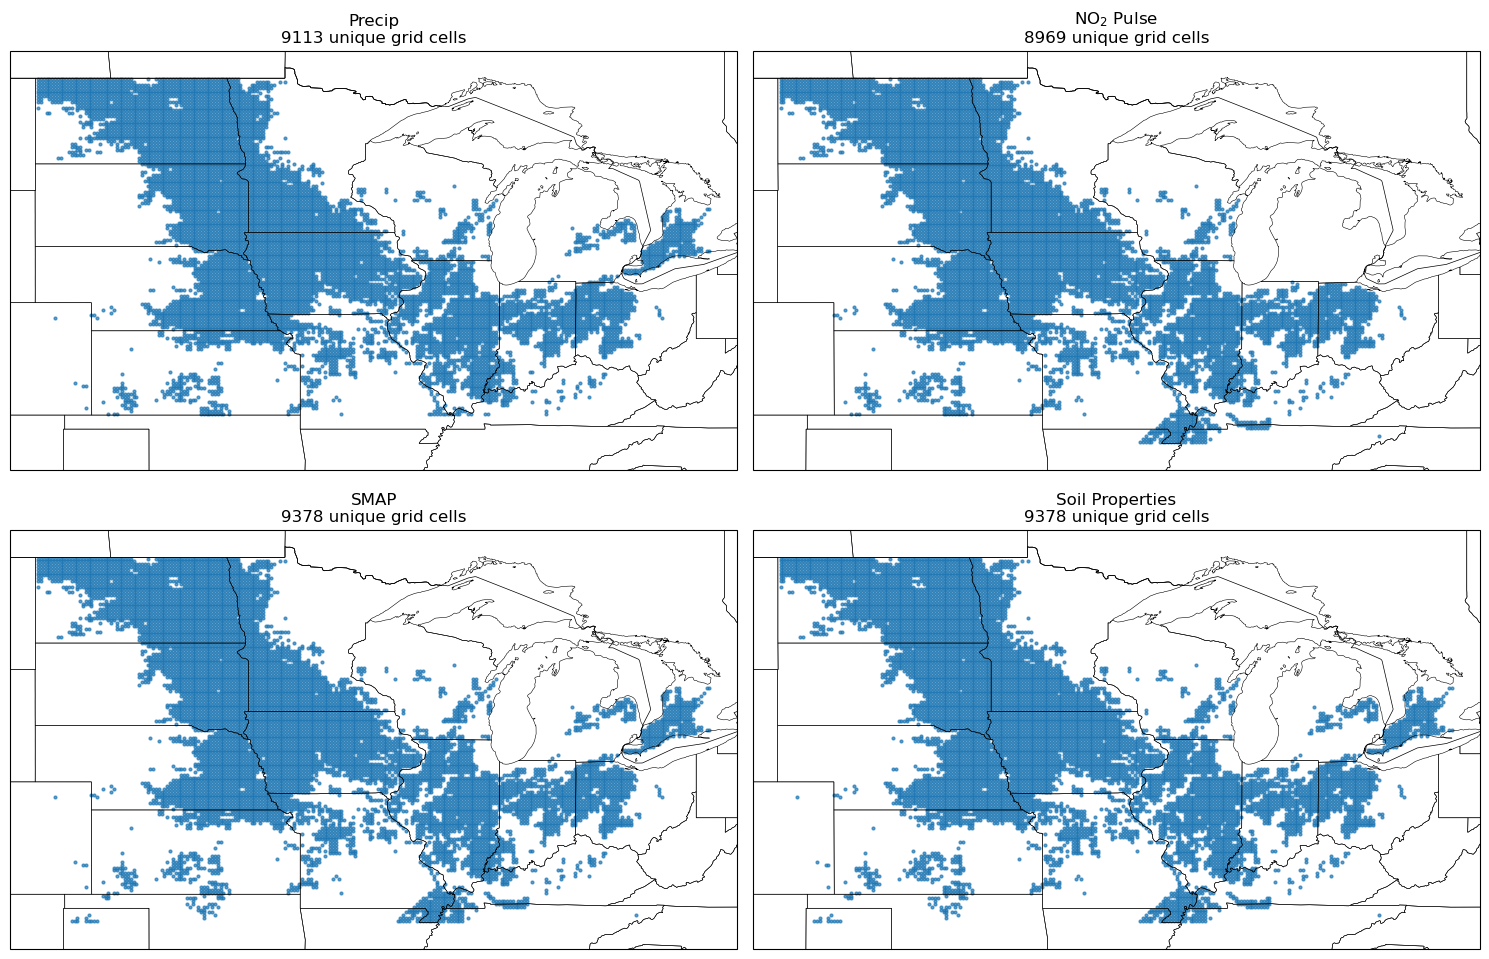

In [8]:
precip_pts = precip_df[["grid_lat", "grid_lon"]].drop_duplicates().copy()
no2_pts = no2_pulse_df[["grid_lat", "grid_lon"]].drop_duplicates().copy()
smap_pts = smap_df[["grid_lat", "grid_lon"]].drop_duplicates().copy()
soil_pts = soil_props_df[["grid_lat", "grid_lon"]].drop_duplicates().copy()

all_lons = pd.concat([precip_pts["grid_lon"], no2_pts["grid_lon"],
                      smap_pts["grid_lon"], soil_pts["grid_lon"]])
all_lats = pd.concat([precip_pts["grid_lat"], no2_pts["grid_lat"],
                      smap_pts["grid_lat"], soil_pts["grid_lat"]])

lon_min, lon_max = all_lons.min() -1, all_lons.max() +1
lat_min, lat_max = all_lats.min() -1, all_lats.max() +1
fig, axes = plt.subplots(2, 2, figsize=(15, 10),subplot_kw={"projection": ccrs.PlateCarree()})

datasets = [
    (precip_pts, "Precip"),
    (no2_pts, "NO$_2$ Pulse"),
    (smap_pts, "SMAP"),
    (soil_pts, "Soil Properties")]

for ax, (pts, title) in zip(axes.ravel(), datasets):
    ax.set_extent([lon_min, lon_max, lat_min, lat_max], crs=ccrs.PlateCarree())
    ax.add_feature(cfeature.COASTLINE, linewidth=0.5)
    ax.add_feature(cfeature.BORDERS, linewidth=0.5)
    ax.add_feature(cfeature.STATES, linewidth=0.4)

    #plot all grid cells
    ax.scatter(
        pts["grid_lon"], pts["grid_lat"],
        s=4, alpha=0.7,
        transform=ccrs.PlateCarree())
    ax.set_title(f"{title}\n{len(pts)} unique grid cells")

plt.tight_layout()
plt.show()

In [9]:
# merge time varying datasets on datetime, grid_lat, and grid_lon 
merge_keys =['datetime','grid_lat','grid_lon']

merged = (precip_df
          .merge(no2_pulse_df, on=merge_keys,how='outer')
          .merge(smap_df, on=merge_keys, how='outer', suffixes=('', '_smap')))

In [10]:
merged

,grid_lat,grid_lon,date,hour,h_precip_mm,datetime,no2_mean,no2_std,no2_count,no2_sem,...,prev_above,run_id,run_len,pulse_start,sm_surface,surface_temp,soil_temp_layer1,LAI,catchment_model_porosity,WFPS_c
0,36.05,-102.75,NaN,NaN,NaN,2024-02-29 22:00:00,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,36.05,-102.65,NaN,NaN,NaN,2024-02-29 22:00:00,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,36.05,-102.55,NaN,NaN,NaN,2024-02-29 22:00:00,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,36.05,-102.25,NaN,NaN,NaN,2024-02-29 22:00:00,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,36.05,-102.15,NaN,NaN,NaN,2024-02-29 22:00:00,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
34489968,48.95,-97.25,2024-07-31,23:00:00,0.230,2024-07-31 23:00:00,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
34489969,48.95,-97.15,2024-07-31,23:00:00,0.115,2024-07-31 23:00:00,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
34489970,48.95,-97.05,2024-07-31,23:00:00,0.075,2024-07-31 23:00:00,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
34489971,48.95,-96.95,2024-07-31,23:00:00,0.025,2024-07-31 23:00:00,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [11]:
# merging static soil property data on lat and lon only because has no datetime aspect 
merged = merged.merge(soil_props_df, on=['grid_lat', 'grid_lon'], how='left')

In [12]:
# adding state information 
#spatially join unique grid points to state polygons, then map back to merged
states = states[['STUSPS', 'NAME', 'geometry']].rename(columns={'STUSPS': 'state', 'NAME': 'state_name'}).to_crs(epsg=4326)


In [13]:
#need a gdf w/ unique lat/lon grid points
unique_pts = merged[['grid_lat', 'grid_lon']].drop_duplicates().copy()
unique_pts['geometry'] = gpd.points_from_xy(unique_pts['grid_lon'], unique_pts['grid_lat'])
pts_gdf = gpd.GeoDataFrame(unique_pts, geometry='geometry', crs='EPSG:4326')

#spatial join
pts_with_state =gpd.sjoin(pts_gdf, states,how='left', predicate='within') \
        [['grid_lat', 'grid_lon', 'state', 'state_name']]

#merge state cols back to og df 
merged = merged.merge(pts_with_state, on=['grid_lat','grid_lon'], how='left')

n_unmatched = merged['state'].isna().sum()
if n_unmatched > 0:
    print(f"note: {n_unmatched} rows had no matching state (maybe coastal/border grid points fall outside polygon boundaries)")

note: 900130 rows had no matching state (maybe coastal/border grid points fall outside polygon boundaries)


In [14]:
merged

,grid_lat,grid_lon,date,hour,h_precip_mm,datetime,no2_mean,no2_std,no2_count,no2_sem,...,pct_sand,pct_sandy_clay,pct_sandy_clay_loam,pct_sandy_loam,pct_silt,pct_silt_loam,pct_silty_clay,pct_silty_clay_loam,state,state_name_y
0,36.05,-102.75,NaN,NaN,NaN,2024-02-29 22:00:00,NaN,NaN,NaN,NaN,...,0.0,0.0,1.388889,59.722222,0.0,0.0,0.000000,0.000000,TX,Texas
1,36.05,-102.65,NaN,NaN,NaN,2024-02-29 22:00:00,NaN,NaN,NaN,NaN,...,0.0,0.0,6.060606,52.272727,0.0,0.0,0.000000,0.000000,TX,Texas
2,36.05,-102.55,NaN,NaN,NaN,2024-02-29 22:00:00,NaN,NaN,NaN,NaN,...,0.0,0.0,6.250000,72.222222,0.0,0.0,0.000000,0.000000,TX,Texas
3,36.05,-102.25,NaN,NaN,NaN,2024-02-29 22:00:00,NaN,NaN,NaN,NaN,...,0.0,0.0,0.757576,3.030303,0.0,0.0,0.000000,0.000000,TX,Texas
4,36.05,-102.15,NaN,NaN,NaN,2024-02-29 22:00:00,NaN,NaN,NaN,NaN,...,0.0,0.0,0.694444,2.083333,0.0,0.0,0.000000,27.083333,TX,Texas
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
34489968,48.95,-97.25,2024-07-31,23:00:00,0.230,2024-07-31 23:00:00,NaN,NaN,NaN,NaN,...,0.0,0.0,0.000000,0.000000,0.0,0.0,77.272727,22.727273,ND,North Dakota
34489969,48.95,-97.15,2024-07-31,23:00:00,0.115,2024-07-31 23:00:00,NaN,NaN,NaN,NaN,...,0.0,0.0,0.000000,0.000000,0.0,0.0,36.111111,59.027778,MN,Minnesota
34489970,48.95,-97.05,2024-07-31,23:00:00,0.075,2024-07-31 23:00:00,NaN,NaN,NaN,NaN,...,0.0,0.0,0.000000,0.000000,0.0,0.0,12.878788,0.757576,MN,Minnesota
34489971,48.95,-96.95,2024-07-31,23:00:00,0.025,2024-07-31 23:00:00,NaN,NaN,NaN,NaN,...,0.0,0.0,0.000000,25.000000,0.0,0.0,0.000000,0.000000,MN,Minnesota


In [15]:
#adding timezone since now have every point in time instead of just no2 
tf = TimezoneFinder()
 
#need to get timezone or each unique lat/lon 
unique_pts = merged[['grid_lat', 'grid_lon']].drop_duplicates().copy()
unique_pts['timezone'] = unique_pts.apply(lambda r: tf.timezone_at(lat=r['grid_lat'], lng=r['grid_lon']),axis=1)
unique_pts['timezone'] = unique_pts['timezone'].fillna('UTC')
 
#merge timezone string back onto og df
merged =merged.merge(unique_pts, on=['grid_lat', 'grid_lon'], how='left')
 
#group by timezone and apply timezone 
merged['datetime_local'] =pd.NaT  #placeholder
 
utc =pytz.utc
datetime_col =pd.to_datetime(merged['datetime']).dt.tz_localize('UTC')
 
local_times =[]
for tz_name, group_idx in merged.groupby('timezone').groups.items():
    tz = pytz.timezone(tz_name)
    local = datetime_col[group_idx].dt.tz_convert(tz).dt.tz_localize(None)
    local_times.append(local)
 
merged['datetime_local'] = pd.concat(local_times).sort_index()
# merged =merged.drop(columns=['timezone'])
 
print('sample of UTC vs local times:')
print(merged[['grid_lat', 'grid_lon', 'datetime', 'datetime_local','timezone', 'state']].dropna(subset=['datetime']).head(10))

sample of UTC vs local times:
   grid_lat  grid_lon            datetime      datetime_local  \
0     36.05   -102.75 2024-02-29 22:00:00 2024-02-29 16:00:00   
1     36.05   -102.65 2024-02-29 22:00:00 2024-02-29 16:00:00   
2     36.05   -102.55 2024-02-29 22:00:00 2024-02-29 16:00:00   
3     36.05   -102.25 2024-02-29 22:00:00 2024-02-29 16:00:00   
4     36.05   -102.15 2024-02-29 22:00:00 2024-02-29 16:00:00   
5     36.05   -102.05 2024-02-29 22:00:00 2024-02-29 16:00:00   
6     36.05   -101.95 2024-02-29 22:00:00 2024-02-29 16:00:00   
7     36.05   -101.85 2024-02-29 22:00:00 2024-02-29 16:00:00   
8     36.05    -91.15 2024-02-29 22:00:00 2024-02-29 16:00:00   
9     36.05    -91.05 2024-02-29 22:00:00 2024-02-29 16:00:00   

          timezone state  
0  America/Chicago    TX  
1  America/Chicago    TX  
2  America/Chicago    TX  
3  America/Chicago    TX  
4  America/Chicago    TX  
5  America/Chicago    TX  
6  America/Chicago    TX  
7  America/Chicago    TX  
8  America/

In [18]:
merged = merged.sort_values(merge_keys).reset_index(drop=True)

print('What the merged df is and looks like:') 
print(f'Shape: {merged.shape}')
print(f'\nColumns ({len(merged.columns)}):')
print(merged.columns.tolist())
print('\nFirst 5 rows:')
print(merged.head())
print('\nNull counts:')
print(merged.isnull().sum())

What the merged df is and looks like:
Shape: (34489973, 60)

Columns (60):
['grid_lat', 'grid_lon', 'date', 'hour', 'h_precip_mm', 'datetime', 'no2_mean', 'no2_std', 'no2_count', 'no2_sem', 'eff_cloud_fraction_mean', 'eff_cloud_fraction_std', 'amf_cloud_fraction_mean', 'amf_cloud_fraction_std', 'snow_ice_fraction_mean', 'snow_ice_fraction_std', 'cv_no2', 'datetime_utc', 'datetime_local', 'local_hour', 'state_name_x', 'no2_scaled_by_hour', 'rolling_mean', 'rolling_std', 'pulse_threshold', 'above_3sd', 'prev_above', 'run_id', 'run_len', 'pulse_start', 'sm_surface', 'surface_temp', 'soil_temp_layer1', 'LAI', 'catchment_model_porosity', 'WFPS_c', 'clay_percent', 'sand_percent', 'silt_percent', 'ksat', 'ph', 'soil_om_kg_m2', 'bulk_density', 'water_storage', 'dominant_texture', 'pct_clay', 'pct_clay_loam', 'pct_loam', 'pct_loamy_sand', 'pct_sand', 'pct_sandy_clay', 'pct_sandy_clay_loam', 'pct_sandy_loam', 'pct_silt', 'pct_silt_loam', 'pct_silty_clay', 'pct_silty_clay_loam', 'state', 'state_n

In [19]:
merged['state_name_x'].unique()

array([nan, 'Kansas', 'Missouri', 'Nebraska', 'Iowa', 'South Dakota',
       'Wisconsin', 'Minnesota', 'North Dakota', 'Illinois', 'Tennessee',
       'Arkansas', 'Kentucky', 'Indiana', 'Ohio'], dtype=object)

In [20]:
merged.columns

Index(['grid_lat', 'grid_lon', 'date', 'hour', 'h_precip_mm', 'datetime',
       'no2_mean', 'no2_std', 'no2_count', 'no2_sem',
       'eff_cloud_fraction_mean', 'eff_cloud_fraction_std',
       'amf_cloud_fraction_mean', 'amf_cloud_fraction_std',
       'snow_ice_fraction_mean', 'snow_ice_fraction_std', 'cv_no2',
       'datetime_utc', 'datetime_local', 'local_hour', 'state_name_x',
       'no2_scaled_by_hour', 'rolling_mean', 'rolling_std', 'pulse_threshold',
       'above_3sd', 'prev_above', 'run_id', 'run_len', 'pulse_start',
       'sm_surface', 'surface_temp', 'soil_temp_layer1', 'LAI',
       'catchment_model_porosity', 'WFPS_c', 'clay_percent', 'sand_percent',
       'silt_percent', 'ksat', 'ph', 'soil_om_kg_m2', 'bulk_density',
       'water_storage', 'dominant_texture', 'pct_clay', 'pct_clay_loam',
       'pct_loam', 'pct_loamy_sand', 'pct_sand', 'pct_sandy_clay',
       'pct_sandy_clay_loam', 'pct_sandy_loam', 'pct_silt', 'pct_silt_loam',
       'pct_silty_clay', 'pct_silty_

In [21]:
merged_filtered = merged.drop(columns=['datetime_utc', 'state_name_x', 'timezone'])
merged_filtered = merged_filtered.rename(columns={'state_name_y': 'state_name'})

states_to_keep = ['Missouri', 'Iowa', 'Michigan', 'South Dakota','Kansas', 'Nebraska', 'Wisconsin', 'Minnesota',
                  'North Dakota', 'Illinois', 'Tennessee', 'Arkansas','Kentucky', 'Indiana', 'Ohio']

merged_filtered = merged_filtered[ merged_filtered['state_name'].isin(states_to_keep)]

In [22]:
merged_filtered['state_name'].unique()

array(['Arkansas', 'Missouri', 'Tennessee', 'Kentucky', 'Kansas',
       'Illinois', 'Indiana', 'Ohio', 'Nebraska', 'Iowa', 'Michigan',
       'South Dakota', 'Wisconsin', 'Minnesota', 'North Dakota'],
      dtype=object)

### reasoning for missing values 
* precip-- maybe had no precip at an hour 
* tempo-- nighttime, cloud fraction
* tempo rolling means-- needs at least 50 observations to have a high no2 amount
* state-- some places are o"utside of the US
* soil types-- maybe points outside the US 

In [23]:
#saving merged dataframe
output_file = '/global/scratch/users/toireasamarie/0.1x0.1_deg_gridded_datasets/final_datasets/a10_lowCF_scaled_merged_all_datasets_allcols.parquet'
merged_filtered.to_parquet(output_file, engine='pyarrow', index=False)
print(f"\nSaved to: {output_file}")


Saved to: /global/scratch/users/toireasamarie/0.1x0.1_deg_gridded_datasets/final_datasets/a10_lowCF_scaled_merged_all_datasets_allcols.parquet
